In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from russian_rates.analysis import align_ruonia_with_key_rate
from statsmodels.tsa.stattools import adfuller, kpss
from scipy.stats import skew, kurtosis, jarque_bera

from russian_rates.models import (
    prepare_transitions,
    calibrate_profile,
    standardized_residuals,
    conditional_moments
)

In [2]:
ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").exists()
)

DATA_DIR = ROOT / "data" / "processed"

ruonia = pd.read_parquet(DATA_DIR / "ruonia.parquet")
key_rate = pd.read_parquet(DATA_DIR / "key_rate.parquet")

df = align_ruonia_with_key_rate(ruonia, key_rate)

# Убираем даты, для которых неизвестна ключевая ставка
df = df.dropna(subset=["key_rate_pct"]).copy()
df = df.sort_values("date").reset_index(drop=True)

# Спред в процентных пунктах и долях единицы
df["spread_decimal"] = df["spread_pp"] / 100

assert not df["date"].duplicated().any()

display(df.head())
display(df.tail())

,date,ruonia_pct,key_rate_pct,spread_pp,spread_decimal
0,2014-01-09,5.51,5.5,0.01,0.0001
1,2014-01-10,5.84,5.5,0.34,0.0034
2,2014-01-13,6.31,5.5,0.81,0.0081
3,2014-01-14,5.69,5.5,0.19,0.0019
4,2014-01-15,5.60,5.5,0.10,0.0010


,date,ruonia_pct,key_rate_pct,spread_pp,spread_decimal
3161,2026-11-16,13.88,14.0,-0.12,-0.0012
3162,2026-11-17,13.89,14.0,-0.11,-0.0011
3163,2026-11-18,13.96,14.0,-0.04,-0.0004
3164,2026-11-19,14.00,14.0,0.00,0.0000
3165,2026-11-20,14.07,14.0,0.07,0.0007


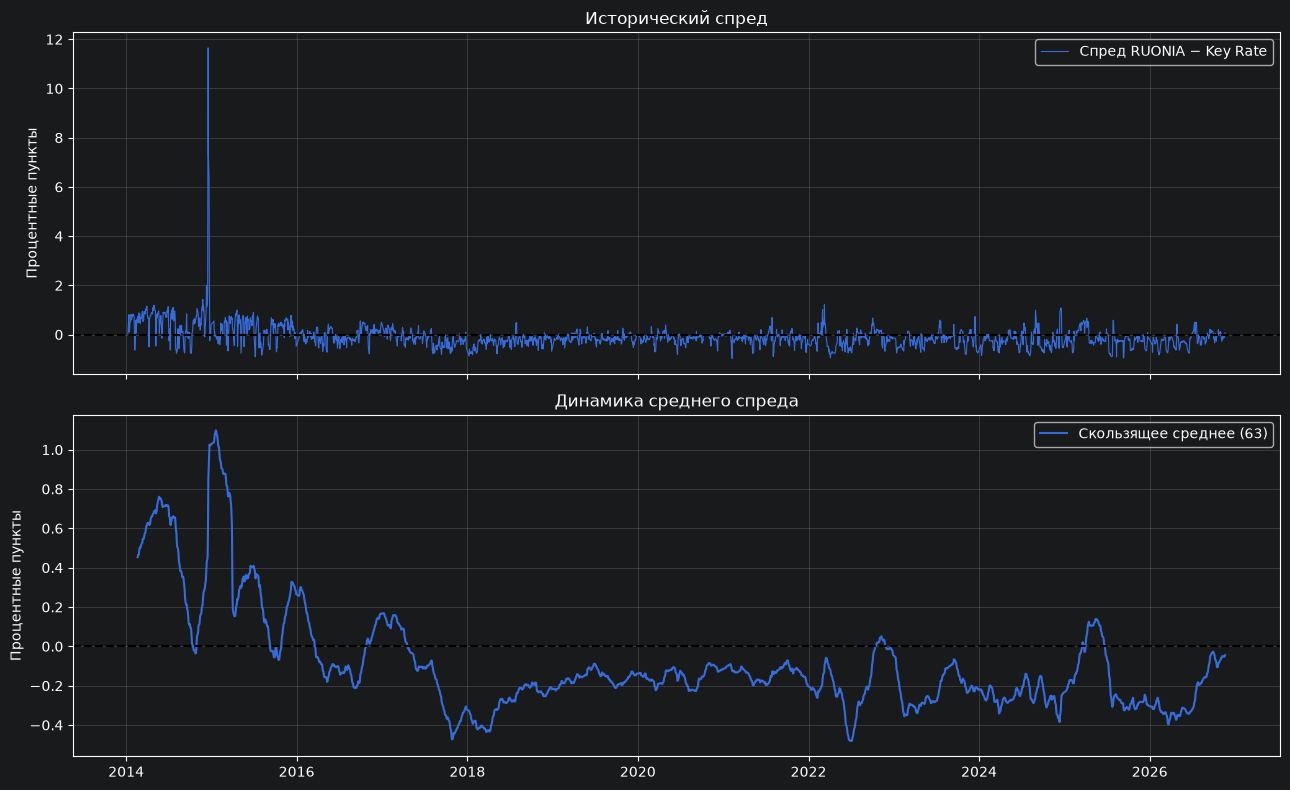

In [3]:
spread = df.set_index("date")["spread_pp"]

# Среднее за 63 наблюдения (~3 месяца)
rolling_mean = spread.rolling(
    window=63,
    min_periods=30
).mean()

fig, axes = plt.subplots(
    2, 1, figsize=(13, 8), sharex=True
)

axes[0].plot(
    spread.index,
    spread,
    linewidth=0.8,
    label="Спред RUONIA − Key Rate"
)

axes[0].axhline(
    0, color="black", linestyle="--"
)

axes[0].set_ylabel("Процентные пункты")
axes[0].set_title("Исторический спред")
axes[0].legend()

axes[1].plot(
    spread.index,
    rolling_mean,
    label="Скользящее среднее (63)",
)

axes[1].axhline(
    0, color="black", linestyle="--"
)

axes[1].set_ylabel("Процентные пункты")
axes[1].set_title("Динамика среднего спреда")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
periods = {
    "2014–2026": ("2014-01-01", None),
    "2016–2021": ("2016-01-01", "2022-01-01"),
    "2022–2026": ("2022-01-01", None),
    "2023–2026": ("2023-01-01", None),
}

results = []

for name, (start, end) in periods.items():
    subset = df.loc[df["date"] >= start].copy()

    if end is not None:
        subset = subset.loc[subset["date"] < end]

    s = subset["spread_pp"]

    results.append({
        "Период": name,
        "Наблюдений": len(s),
        "Среднее, п.п.": s.mean(),
        "Медиана, п.п.": s.median(),
        "Std, п.п.": s.std(),
        "Минимум": s.min(),
        "Максимум": s.max(),
        "ACF(1)": s.autocorr(1),
    })

spread_stats = pd.DataFrame(results)

display(spread_stats.round(4))

,Период,Наблюдений,"Среднее, п.п.","Медиана, п.п.","Std, п.п.",Минимум,Максимум,ACF(1)
0,2014–2026,3166,-0.0893,-0.14,0.4766,-0.97,11.65,0.8621
1,2016–2021,1470,-0.1606,-0.16,0.2274,-0.97,0.69,0.7827
2,2022–2026,1204,-0.2039,-0.21,0.3242,-0.95,1.21,0.8535
3,2023–2026,958,-0.2111,-0.23,0.3171,-0.95,1.08,0.8516


In [5]:
df["delta_key_pp"] = df["key_rate_pct"].diff()

df["policy_changed"] = (
    df["delta_key_pp"].abs() > 1e-9
)

df["abs_spread"] = df["spread_pp"].abs()

event_stats = df.groupby("policy_changed").agg(
    observations=("spread_pp", "count"),
    mean_spread=("spread_pp", "mean"),
    mean_abs_spread=("abs_spread", "mean"),
    median_spread=("spread_pp", "median"),
    std_spread=("spread_pp", "std"),
)

display(event_stats.round(4))

,observations,mean_spread,mean_abs_spread,median_spread,std_spread
policy_changed,,,,,
False,3101,-0.0900,0.3069,-0.14,0.4774
True,65,-0.0586,0.3229,-0.16,0.4418


In [6]:
test_periods = {
    "2014–2026": ("2014-01-01", None),
    "2016–2021": ("2016-01-01", "2022-01-01"),
    "2023–2026": ("2023-01-01", None),
}

results = []

for name, (start, end) in test_periods.items():
    subset = df[df["date"] >= start]

    if end is not None:
        subset = subset[subset["date"] < end]

    s = subset["spread_pp"].dropna()

    # ADF: H0 — единичный корень
    adf = adfuller(
        s,
        regression="c",
        autolag="AIC"
    )

    # KPSS: H0 — стационарность уровня
    kpss_result = kpss(
        s,
        regression="c",
        nlags="auto"
    )

    results.append({
        "Период": name,
        "ADF statistic": adf[0],
        "ADF p-value": adf[1],
        "ADF lags": adf[2],
        "KPSS statistic": kpss_result[0],
        "KPSS p-value": kpss_result[1],
    })

stationarity_df = pd.DataFrame(results)

display(stationarity_df.round(4))

C:\Users\bekishev\AppData\Local\Temp\ipykernel_17568\2222268048.py:18: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf = adfuller(
C:\Users\bekishev\AppData\Local\Temp\ipykernel_17568\2222268048.py:25: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(
C:\Users\bekishev\AppData\Local\Temp\ipykernel_17568\2222268048.py:25: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default

,Период,ADF statistic,ADF p-value,ADF lags,KPSS statistic,KPSS p-value
0,2014–2026,-7.4095,0.0000,18,2.9955,0.0100
1,2016–2021,-4.3429,0.0004,20,0.4221,0.0676
2,2023–2026,-9.5542,0.0000,1,0.1192,0.1000


In [7]:
df["delta_spread_pp"] = df["spread_pp"].diff()

display(
    df.groupby("policy_changed")["delta_spread_pp"]
      .agg(
          count="count",
          mean="mean",
          std="std",
          mean_abs_change=lambda x: x.abs().mean(),
          max_abs_change=lambda x: x.abs().max()
      )
      .round(4)
)

,count,mean,std,mean_abs_change,max_abs_change
policy_changed,,,,,
False,3100,-0.0011,0.2452,0.1234,5.03
True,65,0.0512,0.4277,0.3405,1.36


In [8]:
periods = {
    "2014–2026": ("2014-01-01", None),
    "2016–2021": ("2016-01-01", "2022-01-01"),
    "2023–2026": ("2023-01-01", None),
}

results = []

for name, (start, end) in periods.items():
    subset = df[df["date"] >= start].copy()

    if end is not None:
        subset = subset[subset["date"] < end]

    r_prev, r_next, dt = prepare_transitions(
        subset, "spread_pp"
    )

    fit = calibrate_profile(
        r_prev, r_next, dt,
        a_bounds=(0.001, 200.0)
    )

    results.append({
        "Период": name,
        "a": fit["a"],
        "b, п.п.": fit["b"] * 100,
        "sigma, п.п./√год": fit["sigma"] * 100,
        "Half-life, дней": np.log(2) / fit["a"] * 365,
        "NLL": fit["nll"],
    })

spread_fits = pd.DataFrame(results)
display(spread_fits.round(4))

,Период,a,"b, п.п.","sigma, п.п./√год","Half-life, дней",NLL
0,2014–2026,48.0669,-0.0900,4.6719,5.2635,-14449.1624
1,2016–2021,66.0214,-0.1608,2.6745,3.8321,-7572.8880
2,2023–2026,42.8224,-0.2113,2.9518,5.9081,-4800.2168


In [10]:
diagnostics_results = []
spread_diagnostics = {}

for name, (start, end) in periods.items():
    subset = df[df["date"] >= start].copy()

    if end is not None:
        subset = subset[subset["date"] < end]

    r0, r1, dt = prepare_transitions(
        subset, "spread_pp"
    )

    fit = calibrate_profile(
        r0, r1, dt,
        a_bounds=(0.001, 200.0)
    )

    z = standardized_residuals(
        fit["a"],
        fit["b"],
        fit["sigma"],
        r0,
        r1,
        dt,
    )

    spread_diagnostics[name] = {
        "dates": subset["date"].iloc[1:].to_numpy(),
        "z": z,
        "fit": fit,
    }

    jb = jarque_bera(z)

    diagnostics_results.append({
        "Период": name,
        "Skewness": skew(z),
        "Kurtosis": kurtosis(z, fisher=False),
        "JB": jb.statistic,
        "p-value": jb.pvalue,
        "ACF(1)": pd.Series(z).autocorr(1),
        "ACF(|z|, 1)": pd.Series(np.abs(z)).autocorr(1),
        "|z| > 3": np.sum(np.abs(z) > 3),
        "|z| > 5": np.sum(np.abs(z) > 5),
    })

diagnostics_df = pd.DataFrame(diagnostics_results)

display(diagnostics_df.round(4))

,Период,Skewness,Kurtosis,JB,p-value,ACF(1),"ACF(|z|, 1)",|z| > 3,|z| > 5
0,2014–2026,7.7007,231.5898,6.922184e+06,0.0,0.1403,0.5853,20,6
1,2016–2021,0.0709,5.7583,4.669107e+02,0.0,0.0623,0.2352,15,1
2,2023–2026,0.4336,7.7373,9.248416e+02,0.0,0.1131,0.2880,17,2


In [12]:
source = df.sort_values("date").copy()

source["delta_spread_pp"] = source["spread_pp"].diff()
source["delta_key_pp"] = source["key_rate_pct"].diff()

for name, diag in spread_diagnostics.items():

    extreme = pd.DataFrame({
        "date": pd.to_datetime(diag["dates"]),
        "z": diag["z"]
    })

    extreme = extreme.merge(
        source[
            [
                "date",
                "spread_pp",
                "delta_spread_pp",
                "delta_key_pp",
            ]
        ],
        on="date",
        how="left",
        validate="one_to_one",
    )

    extreme["abs_z"] = extreme["z"].abs()

    print(f"\n{name}")

    display(
        extreme.nlargest(10, "abs_z")[
            [
                "date",
                "spread_pp",
                "delta_spread_pp",
                "delta_key_pp",
                "z",
            ]
        ].round(4)
    )


2014–2026


,date,spread_pp,delta_spread_pp,delta_key_pp,z
236,2014-12-18,11.65,5.03,0.0,25.5484
235,2014-12-17,6.62,4.93,0.0,22.4592
237,2014-12-19,7.30,-4.35,0.0,-12.6541
239,2014-12-23,2.93,-3.43,0.0,-11.4884
241,2014-12-25,-0.25,-1.62,0.0,-6.2797
240,2014-12-24,1.37,-1.56,0.0,-5.1785
62,2014-04-09,-0.50,-1.14,0.0,-4.5791
231,2014-12-11,2.00,0.86,0.0,4.4127
123,2014-07-10,0.44,1.07,0.0,4.3760
238,2014-12-22,6.36,-0.94,0.0,4.1795



2016–2021


,date,spread_pp,delta_spread_pp,delta_key_pp,z
1244,2021-02-09,-0.09,0.88,0.0,5.8183
1361,2021-07-29,0.69,0.58,0.0,4.8724
1364,2021-08-03,-0.89,-0.58,0.0,-4.7154
630,2018-08-01,-0.21,-0.70,0.0,-4.6189
208,2016-11-09,0.01,0.64,0.0,4.3854
81,2016-05-12,0.00,0.62,0.0,4.2424
627,2018-07-27,0.46,0.52,0.0,4.1852
78,2016-05-06,-0.55,-0.51,0.0,-3.8211
736,2018-12-28,-0.68,-0.48,0.0,-3.7936
257,2017-01-25,0.23,0.41,0.0,3.1725



2023–2026


,date,spread_pp,delta_spread_pp,delta_key_pp,z
486,2024-12-20,-0.01,-0.98,0.0,-5.8219
628,2025-07-28,0.48,1.36,-2.0,5.1230
75,2023-04-28,0.03,0.75,0.0,4.7556
660,2025-09-10,-0.93,-0.68,0.0,-4.6911
515,2025-02-11,0.14,0.71,0.0,4.5952
479,2024-12-11,0.31,0.67,0.0,4.4804
406,2024-08-30,0.98,0.53,0.0,4.1353
414,2024-09-11,0.15,0.59,0.0,3.8712
640,2025-08-13,-0.27,0.64,0.0,3.8573
480,2024-12-12,0.80,0.49,0.0,3.7548


In [14]:
train_start = pd.Timestamp("2016-01-01")
test_start = pd.Timestamp("2025-01-01")

work = df.sort_values("date").reset_index(drop=True).copy()

train = work[
    (work["date"] >= train_start)
    & (work["date"] < test_start)
].copy()

# Модель 1 — абсолютная RUONIA
r0, r1, dt = prepare_transitions(
    train, "ruonia_pct"
)

fit_ruonia = calibrate_profile(
    r0, r1, dt,
    a_bounds=(0.001, 20.0),
)

# Модель 2 — спред RUONIA - Key Rate
s0, s1, dt_spread = prepare_transitions(
    train, "spread_pp"
)

fit_spread = calibrate_profile(
    s0, s1, dt_spread,
    a_bounds=(0.001, 200.0),
)

fits = pd.DataFrame([
    {
        "Модель": "Vasicek RUONIA",
        "a": fit_ruonia["a"],
        "b": fit_ruonia["b"] * 100,
        "sigma": fit_ruonia["sigma"] * 100,
    },
    {
        "Модель": "Vasicek Spread",
        "a": fit_spread["a"],
        "b": fit_spread["b"] * 100,
        "sigma": fit_spread["sigma"] * 100,
    },
])

display(fits.round(4))

,Модель,a,b,sigma
0,Vasicek RUONIA,0.0893,21.0720,4.1210
1,Vasicek Spread,54.8764,-0.1791,2.8587


In [15]:
# Предыдущее наблюдение RUONIA
work["ruonia_prev"] = work["ruonia_pct"].shift(1)

# Предыдущий спред
work["spread_prev"] = work["spread_pp"].shift(1)

# Последняя известная ключевая ставка
work["key_prev"] = work["key_rate_pct"].shift(1)

# Интервал между наблюдениями
work["dt_years"] = (
    work["date"].diff().dt.total_seconds()
    / (86400 * 365)
)

# Отбираем тестовую выборку после формирования пар
test = work[work["date"] >= test_start].copy()
test = test.dropna(
    subset=[
        "ruonia_prev",
        "spread_prev",
        "key_prev",
        "dt_years",
    ]
)

assert (test["dt_years"] > 0).all()

dt_test = test["dt_years"].to_numpy()

# 1. Наивная модель
test["pred_naive"] = test["ruonia_prev"]

# 2. Vasicek RUONIA
mu_ruonia, _ = conditional_moments(
    fit_ruonia["a"],
    fit_ruonia["b"],
    fit_ruonia["sigma"],
    test["ruonia_prev"].to_numpy() / 100,
    dt_test,
)

test["pred_vasicek"] = mu_ruonia * 100

# 3. Vasicek Spread
mu_spread, _ = conditional_moments(
    fit_spread["a"],
    fit_spread["b"],
    fit_spread["sigma"],
    test["spread_prev"].to_numpy() / 100,
    dt_test,
)

test["pred_spread"] = (
    test["key_prev"] + mu_spread * 100
)

display(
    test[
        [
            "date",
            "ruonia_pct",
            "pred_naive",
            "pred_vasicek",
            "pred_spread",
        ]
    ].head(10).round(4)
)

,date,ruonia_pct,pred_naive,pred_vasicek,pred_spread
2701,2025-01-09,21.00,20.47,20.4719,20.7712
2702,2025-01-10,20.62,21.00,21.0000,20.9750
2703,2025-01-13,20.49,20.62,20.6203,20.6929
2704,2025-01-14,21.00,20.49,20.4901,20.5362
2705,2025-01-15,20.74,21.00,21.0000,20.9750
2706,2025-01-16,20.85,20.74,20.7401,20.7513
2707,2025-01-17,21.06,20.85,20.8501,20.8459
2708,2025-01-20,21.08,21.06,21.0600,20.9732
2709,2025-01-21,21.18,21.08,21.0800,21.0438
2710,2025-01-22,20.84,21.18,21.1800,21.1299


In [16]:
models = {
    "Naive": "pred_naive",
    "Vasicek RUONIA": "pred_vasicek",
    "Vasicek Spread": "pred_spread",
}

metrics = []

for name, column in models.items():
    errors = (
        test["ruonia_pct"] - test[column]
    ).to_numpy()

    metrics.append({
        "Модель": name,
        "MAE, п.п.": np.mean(np.abs(errors)),
        "RMSE, п.п.": np.sqrt(np.mean(errors**2)),
        "Bias, п.п.": np.mean(errors),
    })

metrics_df = pd.DataFrame(metrics)

display(metrics_df.round(5))

,Модель,"MAE, п.п.","RMSE, п.п.","Bias, п.п."
0,Naive,0.08942,0.14701,-0.01376
1,Vasicek RUONIA,0.08989,0.14723,-0.01529
2,Vasicek Spread,0.10559,0.15864,-0.01683


In [17]:
# Фактическое изменение ключевой ставки
# используется только для ПОСЛЕДУЮЩЕЙ оценки ошибок
test["policy_changed"] = (
    (test["key_rate_pct"] - test["key_prev"]).abs() > 1e-9
)

rows = []

for changed, group in test.groupby("policy_changed"):
    for name, column in models.items():

        error = group["ruonia_pct"] - group[column]

        rows.append({
            "Ключевая изменилась": changed,
            "Модель": name,
            "Наблюдений": len(group),
            "MAE": error.abs().mean(),
            "RMSE": np.sqrt((error**2).mean()),
        })

event_metrics = pd.DataFrame(rows)

display(event_metrics.round(4))

,Ключевая изменилась,Модель,Наблюдений,MAE,RMSE
0,False,Naive,455,0.0848,0.1368
1,False,Vasicek RUONIA,455,0.0852,0.1370
2,False,Vasicek Spread,455,0.0987,0.1416
3,True,Naive,10,0.3000,0.3910
4,True,Vasicek RUONIA,10,0.3016,0.3919
5,True,Vasicek Spread,10,0.4209,0.5085
